Шаг 1. Подготовка программной среды.

In [37]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from skimage.feature import hog

Настройки

In [38]:
# Изображение подшипника
IMAGE_PATH = '18_final_processed.png'

# Каталог для сохранения результатов
RESULTS_DIR = Path('results')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

In [39]:
img = cv2.imread(IMAGE_PATH)

if img is None:
    raise FileNotFoundError(
        'Изображение не найдено'
    )

height, width = img.shape[:2]

channels = (
    1
    if img.ndim == 2
    else img.shape[2]
)

print('Параметры исходного изображения')
print('--------------------------------')
print('Ширина:', width)
print('Высота:', height)
print('Количество каналов:', channels)
print('Тип данных:', img.dtype)

cv2.imwrite(
    str(RESULTS_DIR / '01_original.png'),
    img
)

Параметры исходного изображения
--------------------------------
Ширина: 640
Высота: 640
Количество каналов: 3
Тип данных: uint8


True

Шаг 2. Выделение границ методом Кэнни. 

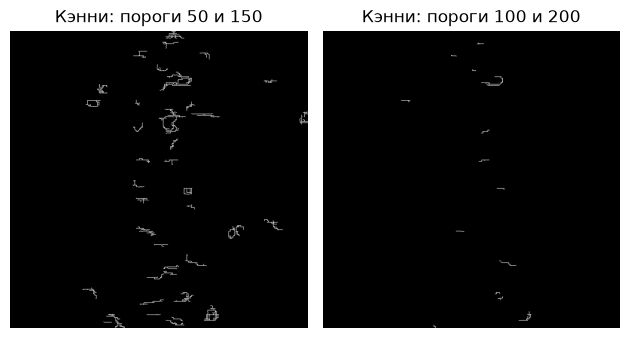

In [40]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
edges1 = cv2.Canny(gray, 50, 150)
edges2 = cv2.Canny(gray, 100, 200)

cv2.imwrite(
    str(RESULTS_DIR / '02_gray.png'),
    gray
)

cv2.imwrite(
    str(RESULTS_DIR / '03_edges1.png'),
    edges1
)

cv2.imwrite(
    str(RESULTS_DIR / '04_edges2.png'),
    edges2
)

plt.subplot(1, 2, 1)
plt.imshow(edges1, cmap="gray")
plt.title("Кэнни: пороги 50 и 150")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edges2, cmap="gray")
plt.title("Кэнни: пороги 100 и 200")
plt.axis("off")

plt.tight_layout()
plt.show()


Шаг 3. Поиск и анализ контуров.

Найдено контуров (S >= 50): 16

№	Площадь	Периметр	BBox (x, y, w, h)
1	102.0	43.3		(428, 611, 13, 13)
2	168.5	59.1		(0, 604, 13, 20)
3	534.0	113.0		(294, 589, 39, 23)
4	540.0	130.6		(0, 569, 26, 33)
5	57.5	38.2		(163, 567, 16, 6)
6	161.5	59.9		(362, 564, 19, 15)
7	89.0	43.7		(342, 548, 13, 12)
8	740.5	123.2		(45, 457, 35, 32)
9	472.5	120.0		(10, 445, 35, 29)
10	91.0	44.5		(288, 435, 13, 13)
11	62.5	35.4		(0, 246, 13, 7)
12	496.0	99.3		(330, 186, 22, 29)
13	106.0	45.7		(630, 179, 10, 16)
14	55.0	30.8		(176, 151, 9, 9)
15	185.0	62.5		(361, 103, 23, 12)
16	311.5	80.7		(336, 12, 28, 17)


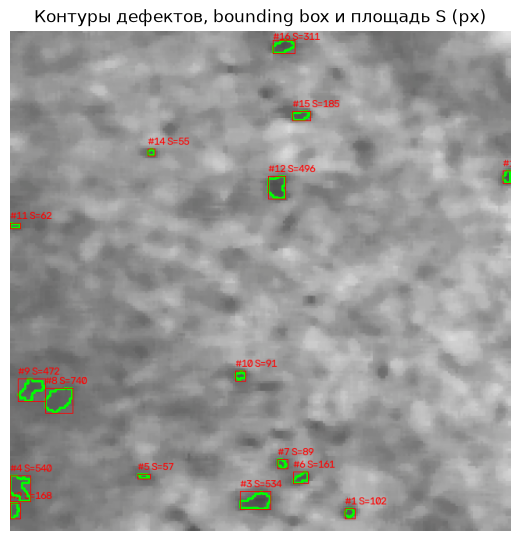

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(640, 640), dtype=uint8)

In [41]:
OBJ_THRESH = 100   # дефекты темнее этого порога
MIN_AREA = 50      # фильтр шума по площади, px

_, obj_mask = cv2.threshold(gray, OBJ_THRESH, 255, cv2.THRESH_BINARY_INV)
obj_mask = cv2.morphologyEx(obj_mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))

contours, _ = cv2.findContours(obj_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

vis = img.copy()
rows = []

for c in contours:
    area = cv2.contourArea(c)
    if area < MIN_AREA:
        continue

    perim = cv2.arcLength(c, True)
    x, y, bw_, bh_ = cv2.boundingRect(c)
    rows.append((len(rows) + 1, area, perim, (x, y, bw_, bh_), c))
    
    cv2.drawContours(vis, [c], -1, (0, 255, 0), 2)
    cv2.rectangle(vis, (x, y), (x + bw_, y + bh_), (0, 0, 255), 1)
    cv2.putText(vis, f'#{len(rows)} S={int(area)}', (x, max(y - 5, 12)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 255), 1)

print(f'Найдено контуров (S >= {MIN_AREA}): {len(rows)}\n')
print(f"№\tПлощадь\tПериметр\tBBox (x, y, w, h)")

for n, a, p, bb, _ in rows:
    print(f"{n}\t{a:.1f}\t{p:.1f}\t\t{bb}")

plt.figure(figsize=(9, 6.5))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title('Контуры дефектов, bounding box и площадь S (px)')
plt.axis('off')
plt.savefig(f'{RESULTS_DIR}/03_contours.png', bbox_inches='tight')
plt.show()

contour_mask = np.zeros_like(gray)
cv2.drawContours(contour_mask, [r[4] for r in rows], -1, 255, -1)   # заливка найденных контуров

Шаг 4. Обнаружение ключевых точек.

Ключевых точек на исходном кадре: 60
Ключевых точек на кадре, повёрнутом на 25°: 52


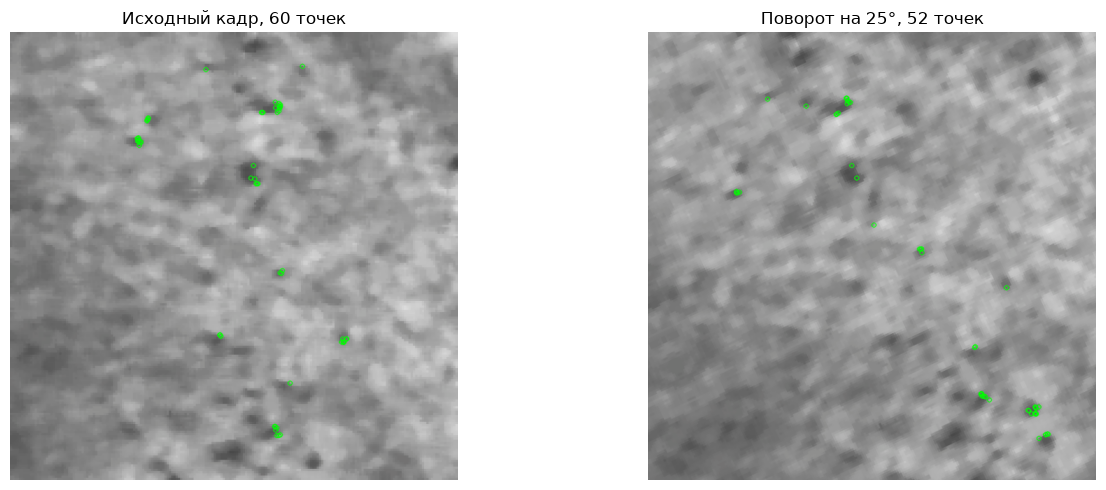

In [42]:
ANGLE = 25
orb = cv2.ORB_create(nfeatures=60)
kp1, des1 = orb.detectAndCompute(gray, None)

# поворот изображения на 25° вокруг центра
M = cv2.getRotationMatrix2D((width / 2, height / 2), ANGLE, 1.0)
rot = cv2.warpAffine(img, M, (width, height), borderMode=cv2.BORDER_REFLECT)
gray_rot = cv2.cvtColor(rot, cv2.COLOR_BGR2GRAY)
kp2, des2 = orb.detectAndCompute(gray_rot, None)

print('Ключевых точек на исходном кадре:', len(kp1))
print(f'Ключевых точек на кадре, повёрнутом на {ANGLE}°:', len(kp2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, im, kp, t in [(axes[0], img, kp1, 'Исходный кадр'), (axes[1], rot, kp2, f'Поворот на {ANGLE}°')]:
    ax.imshow(cv2.cvtColor(cv2.drawKeypoints(im, kp, None, color=(0, 255, 0)), cv2.COLOR_BGR2RGB))
    ax.set_title(f'{t}, {len(kp)} точек'); ax.axis('off')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/04_orb.png', bbox_inches='tight')
plt.show()

Шаг 5. Анализ цветовых и текстурных признаков. 

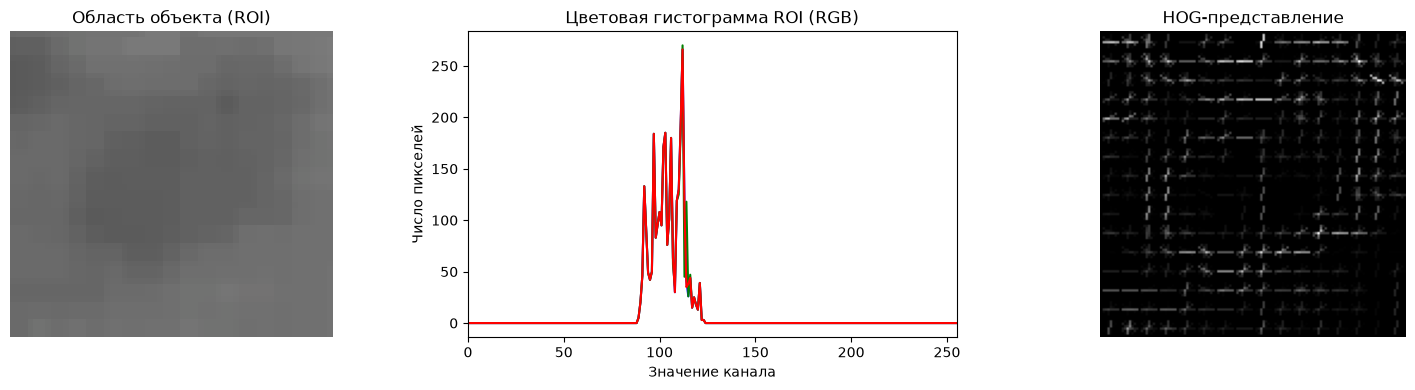

Среднее по каналам B, G, R: [104.5 104.5 104.5]
Дисперсия по каналам B, G, R: [55.6 56.2 55.7]
Среднее по каналам H, S, V: [2.500e+00 1.000e-01 1.045e+02]
Длина HOG-вектора: 8100
Средняя яркость фона: 150.3, дефектов: 92.9, контраст: 57.4


In [43]:
# ROI — самый крупный найденный дефект
if rows:
    big = max(rows, key=lambda r: r[1])
    x, y, bw_, bh_ = big[3]
else:
    x, y, bw_, bh_ = width // 4, height // 4, width // 2, height // 2
pad = 10
x0, y0 = max(x - pad, 0), max(y - pad, 0)
x1, y1 = min(x + bw_ + pad, width), min(y + bh_ + pad, height)
roi = img[y0:y1, x0:x1]

# --- цветовые признаки
colors = ('b', 'g', 'r')
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)); axes[0].set_title('Область объекта (ROI)'); axes[0].axis('off')
for i, col in enumerate(colors):
    hist_c = cv2.calcHist([roi], [i], None, [256], [0, 256])
    axes[1].plot(hist_c, color=col)
axes[1].set_title('Цветовая гистограмма ROI (RGB)')
axes[1].set_xlabel('Значение канала'); axes[1].set_ylabel('Число пикселей'); axes[1].set_xlim([0, 255])

# --- HOG
roi_gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
roi_hog = cv2.resize(roi_gray, (128, 128))
hog_vec, hog_img = hog(roi_hog, orientations=9, pixels_per_cell=(8, 8),
                       cells_per_block=(2, 2), visualize=True)
axes[2].imshow(hog_img, cmap='gray'); axes[2].set_title('HOG-представление'); axes[2].axis('off')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/05_color_hog.png', bbox_inches='tight')
plt.show()

# --- числовые признаки
hsv = cv2.cvtColor(roi, cv2.COLOR_BGR2HSV)
print('Среднее по каналам B, G, R:', roi.reshape(-1, 3).mean(axis=0).round(1))
print('Дисперсия по каналам B, G, R:', roi.reshape(-1, 3).var(axis=0).round(1))
print('Среднее по каналам H, S, V:', hsv.reshape(-1, 3).mean(axis=0).round(1))
print('Длина HOG-вектора:', hog_vec.shape[0])

# контраст дефекта и фона (для примера)
bg_mean = gray[obj_mask == 0].mean()
fg_mean = gray[obj_mask > 0].mean() if (obj_mask > 0).any() else float('nan')
print(f'Средняя яркость фона: {bg_mean:.1f}, дефектов: {fg_mean:.1f}, контраст: {bg_mean - fg_mean:.1f}')

Шаг 6. Бинаризация с плавающим порогом

Расхождение с cv2.cvtColor (веса 0,299/0,587/0,114): max=1, mean=0.09
Ручная бинаризация совпадает с векторной для всех t из [30, 60, 90, 120, 150, 180]


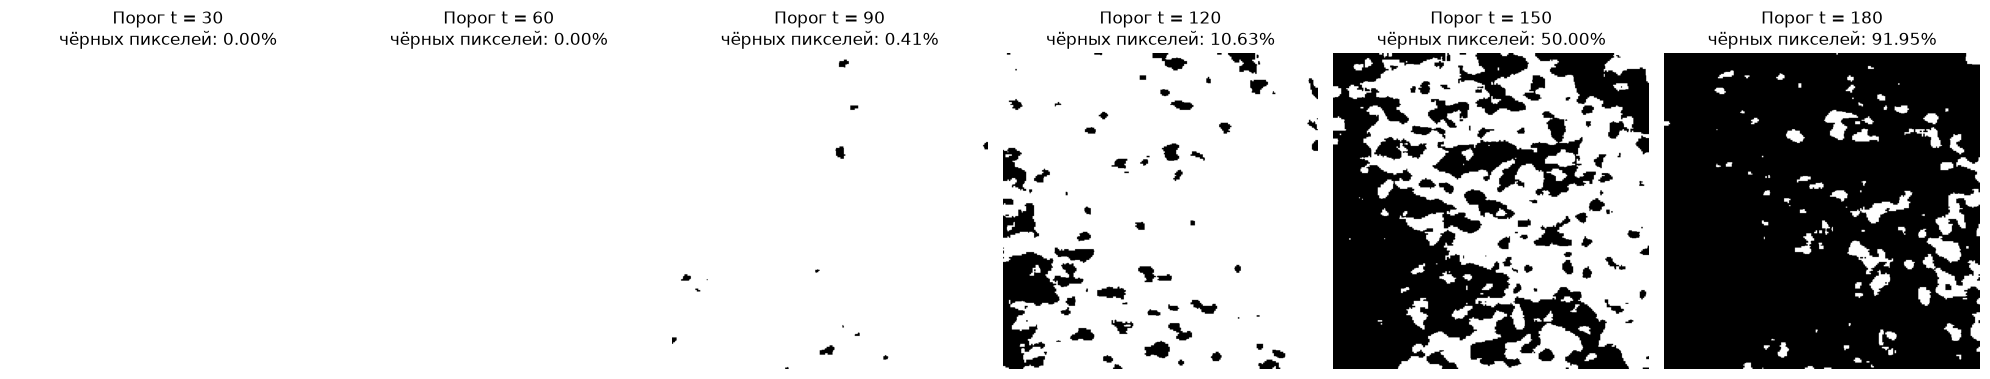

In [44]:
# 6.1. Перевод в оттенки серого по формуле из методички (ручной, поканальный)
b_ch = img[:, :, 0].astype(np.float32)
g_ch = img[:, :, 1].astype(np.float32)
r_ch = img[:, :, 2].astype(np.float32)
Y = np.clip(0.2126 * r_ch + 0.7152 * g_ch + 0.0722 * b_ch, 0, 255).astype(np.uint8)

diff = np.abs(Y.astype(int) - gray.astype(int))
print('Расхождение с cv2.cvtColor (веса 0,299/0,587/0,114): max=%d, mean=%.2f' % (diff.max(), diff.mean()))


# 6.2. Ручная бинаризация двойным циклом
def binarize_manual(gray_img, t):
    rows_, cols_ = gray_img.shape
    bw = np.zeros((rows_, cols_), dtype=np.uint8)
    for i in range(rows_):
        for j in range(cols_):
            if gray_img[i, j] <= t:
                bw[i, j] = 0
            else:
                bw[i, j] = 255
    return bw


T_MIN, T_MAX = 30, 90
THRESHOLDS = [30, 60, 90, 120, 150, 180]

results = {}
for t in THRESHOLDS:
    results[t] = binarize_manual(Y, t)
    cv2.imwrite(f'{RESULTS_DIR}/06_bw_t{t}.png', results[t])

# проверка ручной реализации относительно векторной
for t in THRESHOLDS:
    ref = np.where(Y <= t, 0, 255).astype(np.uint8)
    assert np.array_equal(ref, results[t]), f'Расхождение при t={t}'
print('Ручная бинаризация совпадает с векторной для всех t из', THRESHOLDS)

fig, axes = plt.subplots(1, len(THRESHOLDS), figsize=(20, 4))
for ax, t in zip(axes, THRESHOLDS):
    ax.imshow(results[t], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Порог t = {t}\nчёрных пикселей: {100 * (results[t] == 0).mean():.2f}%')
    ax.axis('off')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/06_threshold_sweep.png', bbox_inches='tight')
plt.show()

Шаг 7. Сравните результат работы своего алгоритма (шаг 6) с контуром объекта,
найденным в общей части работы (шаг 3)

IoU с эталоном (Кэнни) для выбранных порогов:
  t= 30: IoU=0.000, площадь маски=0 px
  t= 60: IoU=0.000, площадь маски=0 px
  t= 90: IoU=0.079, площадь маски=1674 px
  t=120: IoU=0.052, площадь маски=43532 px
  t=150: IoU=0.023, площадь маски=204798 px
  t=180: IoU=0.016, площадь маски=376625 px

Оптимальный порог в диапазоне 30…90: t = 90 (IoU = 0.079)


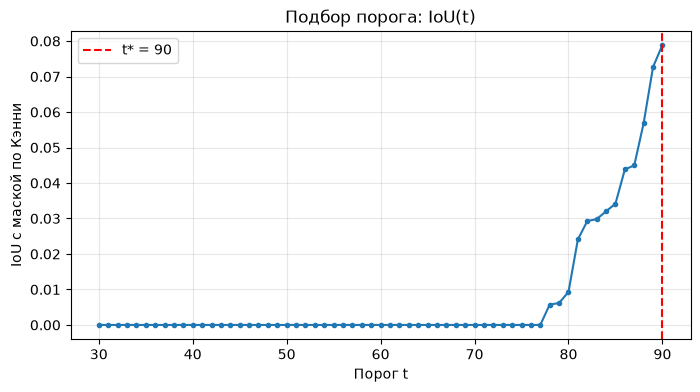

True

In [46]:
# Эталонная маска: границы Кэнни → замыкание → заливка внешних контуров
edges_closed = cv2.morphologyEx(edges1, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))
cnts_c, _ = cv2.findContours(edges_closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
canny_mask = np.zeros_like(gray)
cv2.drawContours(canny_mask, [c for c in cnts_c if cv2.contourArea(c) >= MIN_AREA], -1, 255, -1)


def iou(a, b):
    a, b = a > 0, b > 0
    union = np.logical_or(a, b).sum()
    return np.logical_and(a, b).sum() / union if union else 0.0


ts = list(range(T_MIN, T_MAX + 1))
ious = [iou(Y <= t, canny_mask) for t in ts]
best_t = ts[int(np.argmax(ious))]

print('IoU с эталоном (Кэнни) для выбранных порогов:')
for t in THRESHOLDS:
    print(f'  t={t:3d}: IoU={iou(Y <= t, canny_mask):.3f}, площадь маски={(Y <= t).sum()} px')
print(f'\nОптимальный порог в диапазоне {T_MIN}…{T_MAX}: t = {best_t} (IoU = {max(ious):.3f})')

plt.figure(figsize=(8, 4))
plt.plot(ts, ious, marker='o', ms=3)
plt.axvline(best_t, color='r', ls='--', label=f't* = {best_t}')
plt.xlabel('Порог t'); plt.ylabel('IoU с маской по Кэнни'); plt.grid(alpha=.3); plt.legend()
plt.title('Подбор порога: IoU(t)')
plt.savefig(f'{RESULTS_DIR}/06_iou_vs_t.png', bbox_inches='tight')
plt.show()

best_mask = binarize_manual(Y, best_t)       # 0 — дефект, 255 — поверхность
best_defects = (255 - best_mask)             # инверсия: дефект = 255
cv2.imwrite(f'{RESULTS_DIR}/06_best_mask.png', best_defects)

Площадь маски дефектов, px:
  плавающий порог (t=90): 1674
  контуры шага 3 (порог 100): 4728
  заливка контуров по Кэнни:      6175

IoU(порог t=90, контуры шага 3): 0.348
IoU(порог t=90, Кэнни):          0.079
IoU(контуры шага 3, Кэнни):           0.106


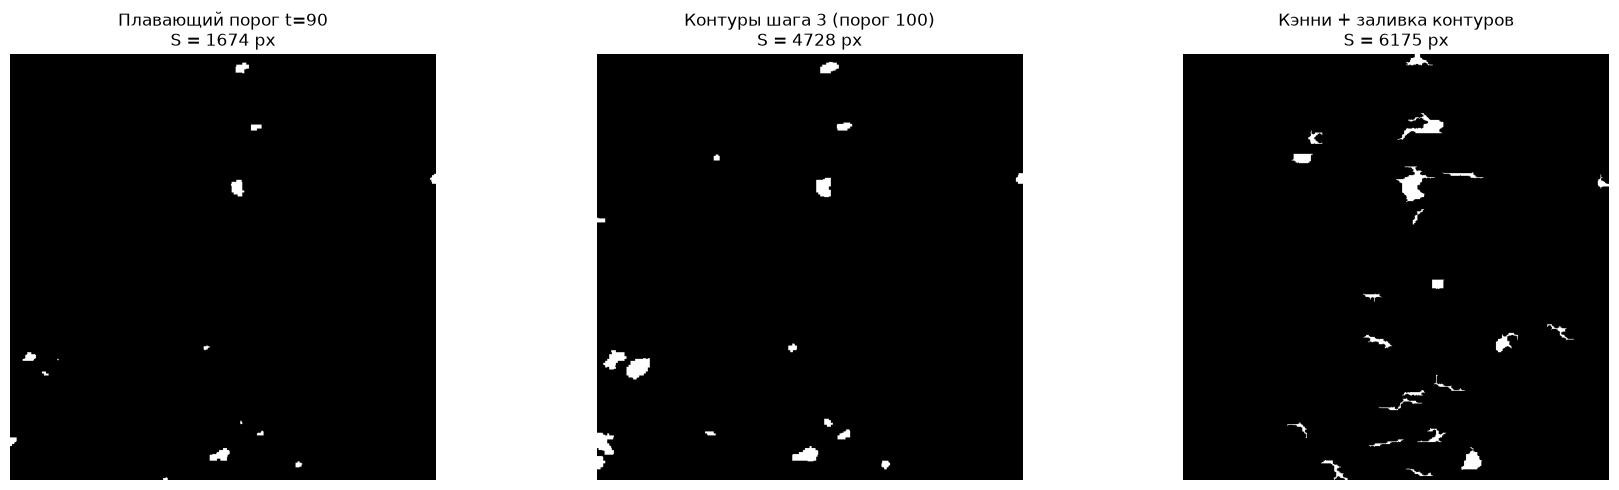

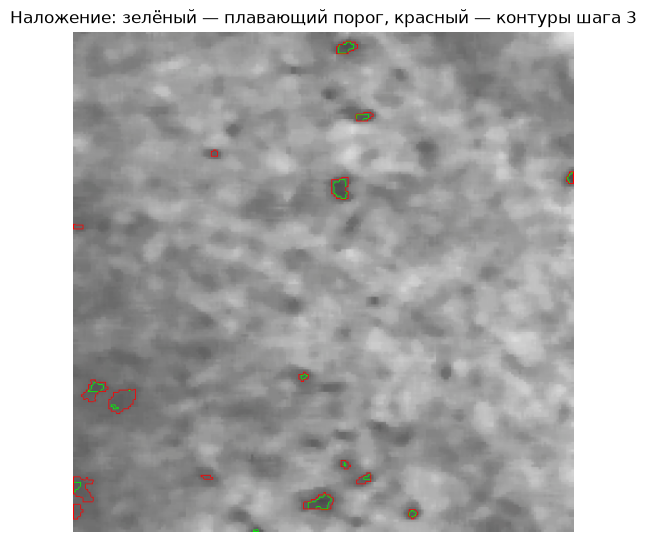

In [47]:
area_thr = int((best_defects > 0).sum())
area_cnt = int((contour_mask > 0).sum())
area_can = int((canny_mask > 0).sum())

print('Площадь маски дефектов, px:')
print(f'  плавающий порог (t={best_t}): {area_thr}')
print(f'  контуры шага 3 (порог {OBJ_THRESH}): {area_cnt}')
print(f'  заливка контуров по Кэнни:      {area_can}')
print()
print(f'IoU(порог t={best_t}, контуры шага 3): {iou(best_defects, contour_mask):.3f}')
print(f'IoU(порог t={best_t}, Кэнни):          {iou(best_defects, canny_mask):.3f}')
print(f'IoU(контуры шага 3, Кэнни):           {iou(contour_mask, canny_mask):.3f}')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, m, t in [(axes[0], best_defects, f'Плавающий порог t={best_t}'),
                 (axes[1], contour_mask, f'Контуры шага 3 (порог {OBJ_THRESH})'),
                 (axes[2], canny_mask, 'Кэнни + заливка контуров')]:
    ax.imshow(m, cmap='gray'); ax.set_title(f'{t}\nS = {int((m > 0).sum())} px'); ax.axis('off')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/07_comparison.png', bbox_inches='tight')
plt.show()

# наложение: зелёный — порог, красный — контуры шага 3
overlay = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).copy()
cs, _ = cv2.findContours(best_defects, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cv2.drawContours(overlay, cs, -1, (0, 255, 0), 1)
cs2, _ = cv2.findContours(contour_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cv2.drawContours(overlay, cs2, -1, (255, 0, 0), 1)
plt.figure(figsize=(9, 6.5)); plt.imshow(overlay)
plt.title('Наложение: зелёный — плавающий порог, красный — контуры шага 3'); plt.axis('off')
plt.savefig(f'{RESULTS_DIR}/07_overlay.png', bbox_inches='tight')
plt.show()

Шаг 8. Сформируйте итоговый перечень признаков и подходов к сегментации,
которые могут быть использованы при разметке данных для выбранного
производственного объекта

In [ ]:
print('ИТОГОВЫЙ ПЕРЕЧЕНЬ (для разметки данных в ЛР №5)')
print('-' * 60)
print('Объект: металлическая поверхность, дефекты — тёмные области/линии.')
print(f'1. Яркость: дефекты темнее поверхности; рабочий порог t* = {best_t} (диапазон 30…180).')
print(f'2. Границы: Canny {50}/{150} после размытия 5x5.')
print(f'3. Геометрия: площадь (фильтр >= {MIN_AREA} px), периметр, bounding box, вытянутость.')
print('4. Ключевые точки: ORB (60 точек), устойчивы к повороту — годятся для слежения/совмещения кадров.')
print('5. Цвет: среднее/дисперсия по BGR и HSV, гистограмма ROI.')
print('6. Текстура: HOG ROI — отличает шлифованный фон от царапин по направлению градиентов.')

ИТОГОВЫЙ ПЕРЕЧЕНЬ (для разметки данных в ЛР №5)
------------------------------------------------------------
Объект: металлическая поверхность, дефекты — тёмные области/линии.
1. Яркость: дефекты темнее поверхности; рабочий порог t* = 90 (диапазон 30…180).
2. Границы: Canny 50/150 после размытия 5x5.
3. Геометрия: площадь (фильтр >= 50 px), периметр, bounding box, вытянутость.
4. Ключевые точки: ORB (60 точек), устойчивы к повороту — годятся для слежения/совмещения кадров.
5. Цвет: среднее/дисперсия по BGR и HSV, гистограмма ROI.
6. Текстура: HOG ROI — отличает шлифованный фон от царапин по направлению градиентов.
Подход к сегментации: плавающий порог как предварительная маска для ускорения ручной разметки;
при неравномерном освещении — адаптивный порог или нейросеть (ЛР №6).
